In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

# Base directory containing all chip folders
DATA_ROOT = "/Users/Rishab/Research"

# Only IR drop folder (ignore everything else)
IR_FOLDER = "IR_drop"

chips = [
    "Vortex-small",
    "Vortex-large",
    "nvdla-large",
    "nvdla-small",
    "openc910-1",
    "RISCY",
    "RISCY-FPU",
    "zero-riscy"
]

In [30]:
def load_ir_drop_files(chip_name):
    folder = os.path.join(DATA_ROOT, chip_name, IR_FOLDER)
    
    files = [
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.endswith(".npz")
    ]
    
    data_list = []
    
    for f in files:
        arr = np.load(f)['data']   # (H, W)
        data_list.append(arr)
    
    return data_list, files

In [31]:
def get_chip_max_values(data_list):
    max_vals = []
    
    for arr in data_list:
        max_vals.append(np.max(arr))
    
    return np.array(max_vals)

In [32]:
def plot_histogram(values, title):
    plt.figure(figsize=(6,4))
    plt.hist(values, bins=50, alpha=0.8)
    plt.title(f"IR Drop Max Distribution — {title}")
    plt.xlabel("Max IR Drop")
    plt.ylabel("Frequency")
    plt.show()

In [33]:
def plot_nvdla_images(data_list, files):

    # Pick sample with largest max IR value
    max_idx = np.argmax([np.max(arr) for arr in data_list])

    sample = data_list[max_idx]

    print("Displaying file:")
    print(files[max_idx])

    print("Shape:", sample.shape)
    print("Max IR:", np.max(sample))

    # ---- Added statistics ----
    print("Mean IR:", np.mean(sample))
    print("99th percentile:", np.percentile(sample, 99))
    print("Std:", np.std(sample))

    fig, axs = plt.subplots(1, 2, figsize=(14,6))

    # -----------------------------------
    # LEFT: contrast-enhanced visualization
    # -----------------------------------
    vmax_percentile = np.percentile(sample, 99)

    im1 = axs[0].imshow(
        sample,
        interpolation='nearest',
        vmax=vmax_percentile
    )

    axs[0].set_title("99th Percentile Scaling")
    axs[0].axis("off")

    fig.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04)

    # -----------------------------------
    # RIGHT: true physical max scaling
    # -----------------------------------
    vmax_true = np.max(sample)

    im2 = axs[1].imshow(
        sample,
        interpolation='nearest',
        vmax=vmax_true
    )

    axs[1].set_title("True Max Scaling")
    axs[1].axis("off")

    fig.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

In [34]:
def inspect_shapes(data_list):
    shape_counts = {}

    for arr in data_list:
        shape = arr.shape

        if shape not in shape_counts:
            shape_counts[shape] = 0

        shape_counts[shape] += 1

    print("\nUnique Shapes Found:\n")

    for shape, count in shape_counts.items():
        print(f"{shape}: {count} files")

In [35]:
data_list, files = load_ir_drop_files("nvdla-large")
inspect_shapes(data_list)


Unique Shapes Found:

(1723, 1718): 4 files
(1583, 1580): 3 files
(1575, 1570): 5 files
(1652, 1651): 4 files
(1644, 1639): 5 files
(1642, 1638): 3 files
(1721, 1716): 2 files
(1510, 1509): 2 files
(1573, 1569): 1 files
(1731, 1729): 3 files



Processing Vortex-small ...
Worst sample:
/Users/Rishab/Research/Vortex-small/IR_drop/Vortex-small_freq_500_mp_2_fpu_50_fpa_1.0_p_1_fi_ar.npz
Max IR: 1386.04


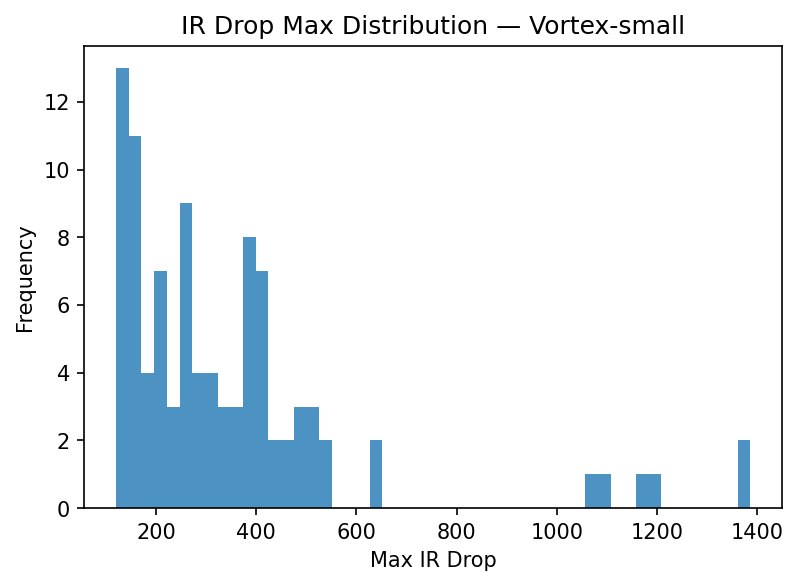


Processing Vortex-large ...
Worst sample:
/Users/Rishab/Research/Vortex-large/IR_drop/Vortex-large_freq_200_mp_2_fpu_50_fpa_1.0_p_2_fi_ar.npz
Max IR: 3248.22


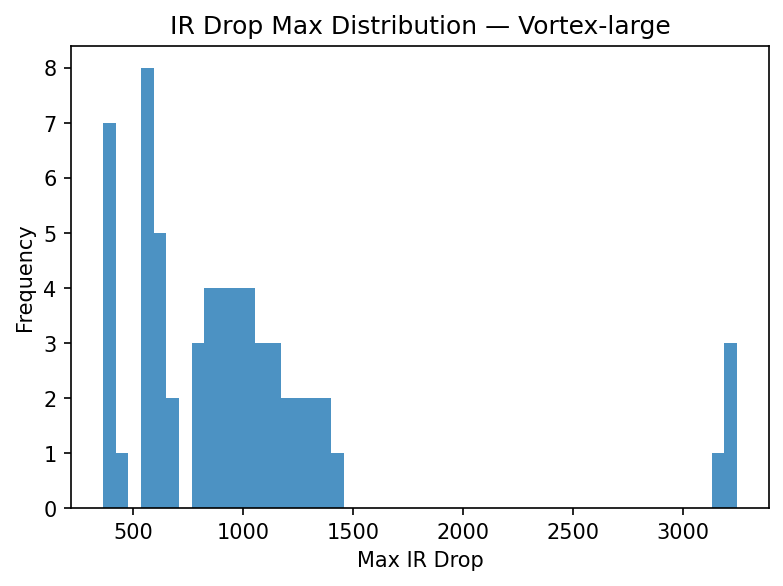


Processing nvdla-large ...
Worst sample:
/Users/Rishab/Research/nvdla-large/IR_drop/nvdla-large_freq_200_mp_1_fpu_55_fpa_1.0_p_1_fi_ar.npz
Max IR: 30821.3


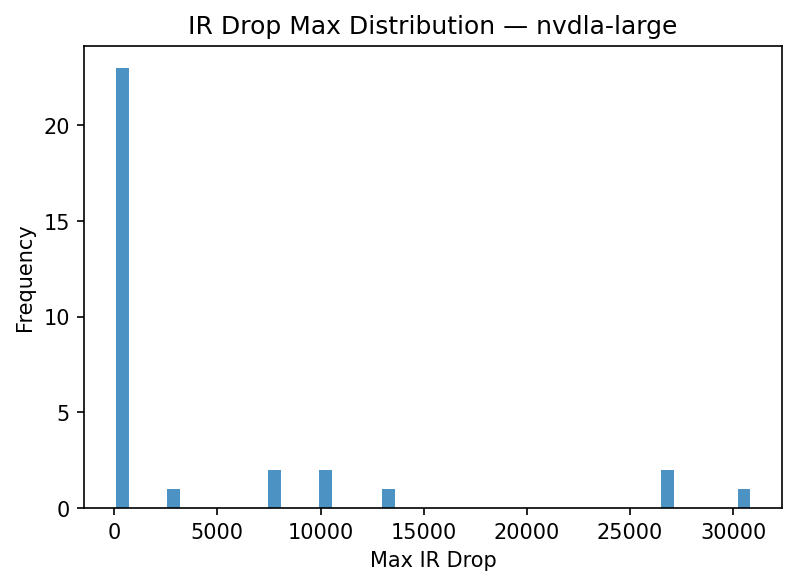

Displaying file:
/Users/Rishab/Research/nvdla-large/IR_drop/nvdla-large_freq_200_mp_1_fpu_55_fpa_1.0_p_1_fi_ar.npz
Shape: (1642, 1638)
Max IR: 30821.3
Mean IR: 24.887580769858328
99th percentile: 51.40051499999994
Std: 669.3805478802773


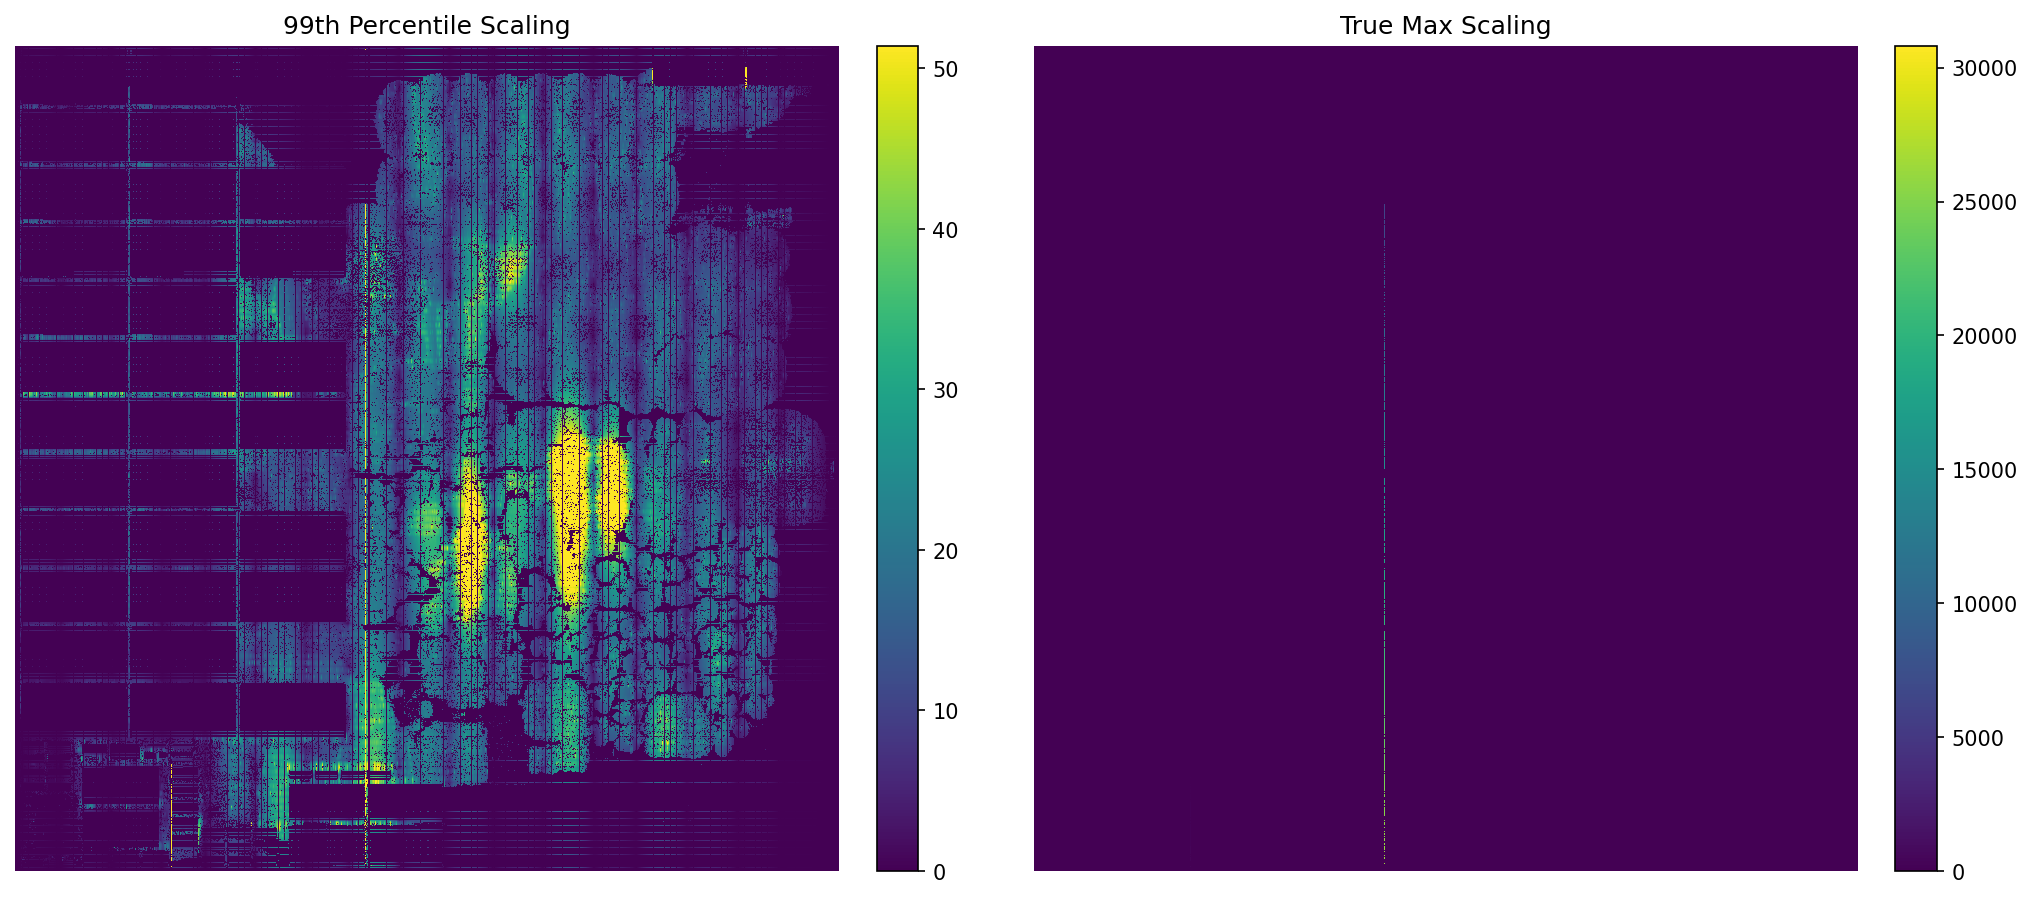


Processing nvdla-small ...
Worst sample:
/Users/Rishab/Research/nvdla-small/IR_drop/nvdla-small_freq_500_mp_2_fpu_65_fpa_1.0_p_1_fi_ar.npz
Max IR: 1038.36


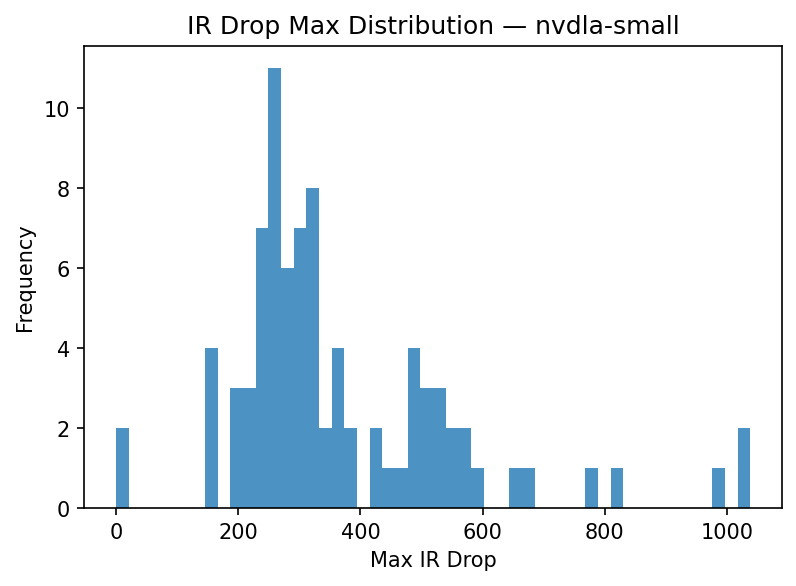


Processing openc910-1 ...
Worst sample:
/Users/Rishab/Research/openc910-1/IR_drop/openc910-1_freq_500_mp_2_fpu_65_fpa_1.0_p_2_fi_ar.npz
Max IR: 2628.57


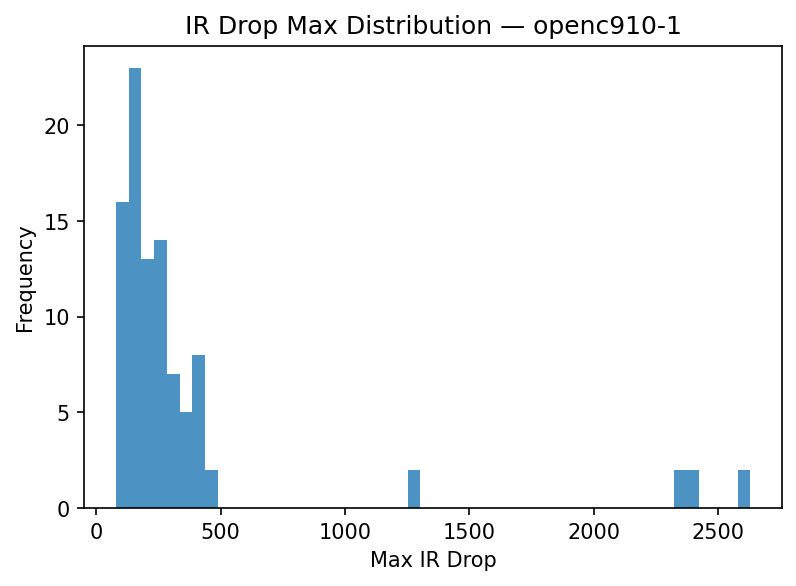


Processing RISCY ...
Worst sample:
/Users/Rishab/Research/RISCY/IR_drop/RISCY_freq_50_mp_3_fpu_70_fpa_2.0_p_2_fi_ar.npz
Max IR: 688.713


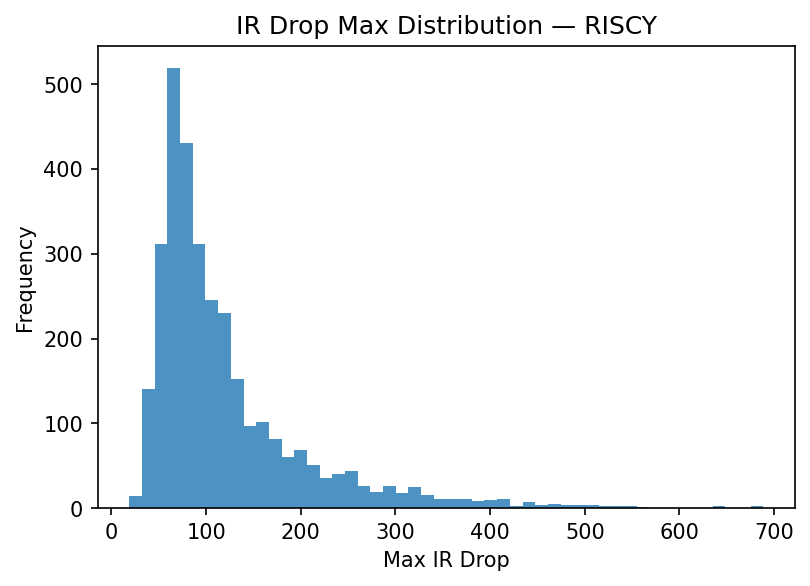


Processing RISCY-FPU ...
Worst sample:
/Users/Rishab/Research/RISCY-FPU/IR_drop/RISCY-FPU_freq_500_mp_1_fpu_70_fpa_1.5_p_1_fi_ar.npz
Max IR: 1230.39


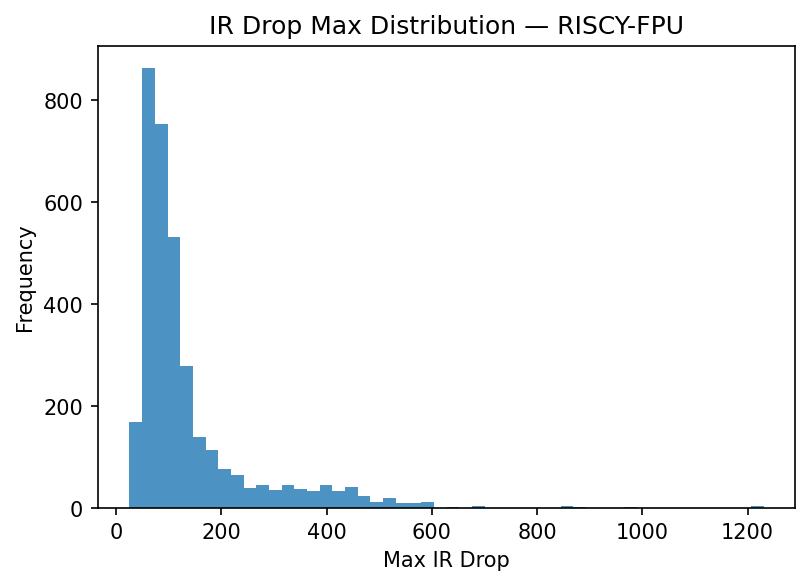


Processing zero-riscy ...
Worst sample:
/Users/Rishab/Research/zero-riscy/IR_drop/zero-riscy_freq_500_mp_3_fpu_55_fpa_2.0_p_3_fi_ar.npz
Max IR: 605.268


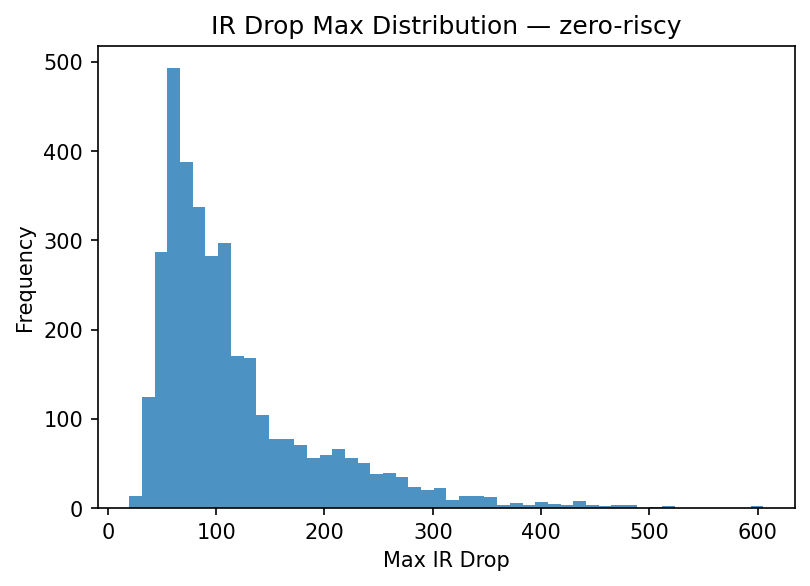

In [36]:
chip_max_dict = {}

for chip in chips:
    print(f"\nProcessing {chip} ...")

    data_list, files = load_ir_drop_files(chip)
    max_vals = get_chip_max_values(data_list)

    top_idx = np.argmax(max_vals)

    print("Worst sample:")
    print(files[top_idx])
    print("Max IR:", max_vals[top_idx])

    chip_max_dict[chip] = max_vals

    # Histogram for EVERY chip
    plot_histogram(max_vals, chip)

    # Special visualization for nvdla-large
    if chip == "nvdla-large":
        plot_nvdla_images(data_list, files)

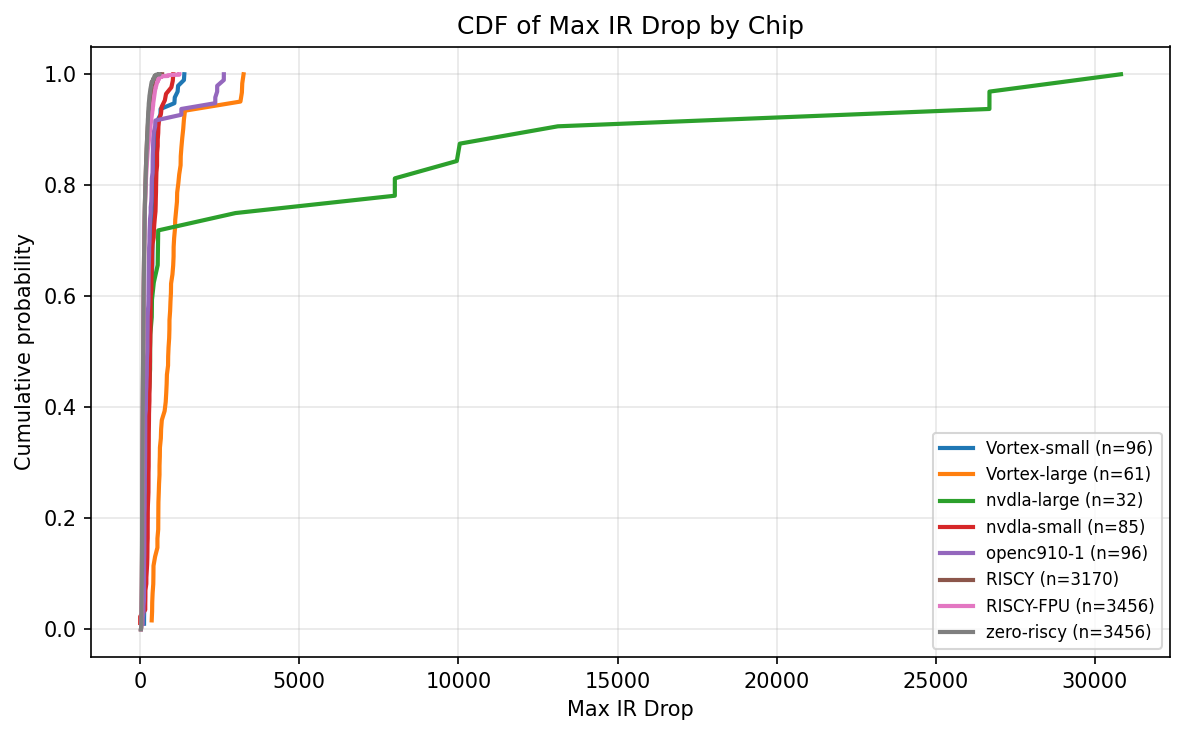

In [37]:
def plot_chip_cdfs(chip_value_dict, xlabel="Max IR Drop"):
    plt.figure(figsize=(8, 5))

    for chip, values in chip_value_dict.items():
        values = np.asarray(values)
        values = values[np.isfinite(values)]

        if len(values) == 0:
            continue

        x = np.sort(values)
        y = np.arange(1, len(x) + 1) / len(x)

        plt.plot(x, y, linewidth=2, label=f"{chip} (n={len(x)})")

    plt.title("CDF of Max IR Drop by Chip")
    plt.xlabel(xlabel)
    plt.ylabel("Cumulative probability")
    plt.grid(True, alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_chip_cdfs(chip_max_dict)